In [1]:
!pip install -q torch torchvision librosa soundfile scipy scikit-learn pandas numpy matplotlib seaborn tqdm
print("Готово. Перезапускать runtime не нужно.")

Готово. Перезапускать runtime не нужно.


In [2]:
import os, zipfile, urllib.request, random
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal as sp_signal
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

# --- Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/ESC50_Project')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project dir: {PROJECT_DIR}")

# --- Seed ---
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# --- Device ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"  GPU: {torch.cuda.get_device_name(0)}, "
          f"VRAM: {p.total_memory/1e9:.1f} GB")
else:
    print("ВНИМАНИЕ: GPU не подключён. Runtime → Change runtime type → GPU")

Mounted at /content/drive
Project dir: /content/drive/MyDrive/ESC50_Project
Device: cuda
  GPU: Tesla T4, VRAM: 15.6 GB


In [3]:
URL      = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"
ZIP_PATH = PROJECT_DIR / "esc50.zip"
DATA_DIR = PROJECT_DIR / "ESC-50-master"

if DATA_DIR.exists() and (DATA_DIR / "meta" / "esc50.csv").exists():
    print(f"Данные уже распакованы: {DATA_DIR}")
else:
    if not ZIP_PATH.exists():
        print("Скачиваем архив (~600 МБ)...")
        def _progress(bn, bs, ts):
            d = bn * bs
            if ts > 0 and bn % 200 == 0:
                print(f"\r  {d/1e6:6.1f} / {ts/1e6:.0f} МБ  ({100*d/ts:5.1f}%)",
                      end="", flush=True)
        urllib.request.urlretrieve(URL, ZIP_PATH, reporthook=_progress)
        print("\n  готово.")
    else:
        print(f"Архив уже есть: {ZIP_PATH}")

    print("Распаковываем...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        with tqdm(total=len(zf.infolist()), desc="  extract", unit="file") as pbar:
            for m in zf.infolist():
                zf.extract(m, PROJECT_DIR); pbar.update(1)

n_wavs = len(list((DATA_DIR / 'audio').glob('*.wav')))
print(f"WAV-файлов: {n_wavs} (должно быть 2000)")

Скачиваем архив (~600 МБ)...

  готово.
Распаковываем...


  extract:   0%|          | 0/2017 [00:00<?, ?file/s]

WAV-файлов: 2000 (должно быть 2000)


Записей: 2000, классов: 50
Примеров на класс: min=40, max=40


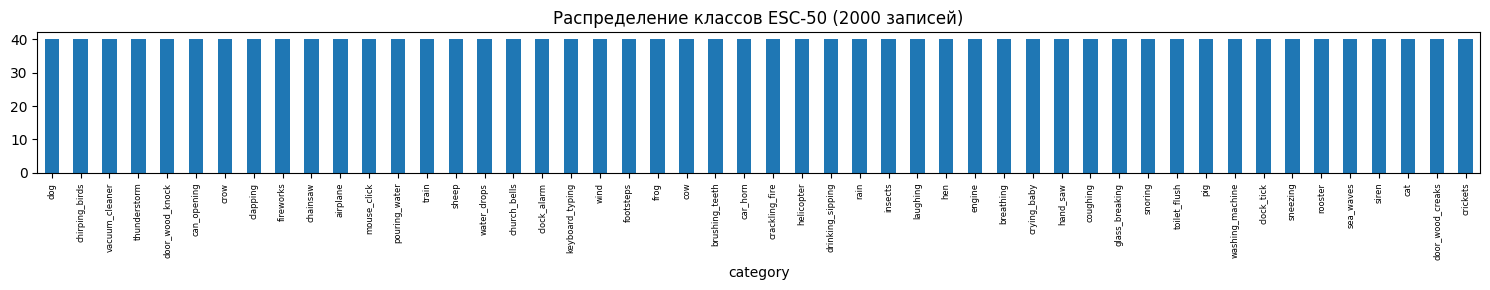

In [4]:
meta = pd.read_csv(DATA_DIR / "meta" / "esc50.csv")

le = LabelEncoder()
meta["label"] = le.fit_transform(meta["category"])

y_all     = meta["label"].values.astype(np.int64)
folds_arr = meta["fold"].values
classes   = list(le.classes_)
folds     = [(np.where(folds_arr != f)[0], np.where(folds_arr == f)[0])
             for f in range(1, 6)]

print(f"Записей: {len(meta)}, классов: {len(classes)}")
print(f"Примеров на класс: min={meta['category'].value_counts().min()}, "
      f"max={meta['category'].value_counts().max()}")

plt.figure(figsize=(15, 3))
meta["category"].value_counts().plot.bar()
plt.title(f"Распределение классов ESC-50 ({len(meta)} записей)")
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "class_distribution.png", dpi=100, bbox_inches="tight")
plt.show()

In [5]:
FEATURES_PATH = PROJECT_DIR / "esc50_features.npz"

if FEATURES_PATH.exists():
    print(f"Признаки уже на Drive: {FEATURES_PATH}")
    print("Загружаем...")
    data = np.load(FEATURES_PATH)
    X_mfcc = data["X_mfcc"]
    X_mel  = data["X_mel"]
    print(f"  X_mfcc: {X_mfcc.shape}, X_mel: {X_mel.shape}")
else:
    SR, N_FFT, HOP = 22050, 2048, 512
    N_MELS         = 128
    TARGET_FRAMES  = 216
    MIN_SAMPLES    = SR   # 1 секунда — минимальная длина для стабильных признаков

    def apply_preprocessing(y, sr=SR, preemphasis=0.97, bp_low=100, bp_high=8000):
        y_pe = np.append(y[0], y[1:] - preemphasis * y[:-1])
        sos  = sp_signal.butter(4, [bp_low, bp_high], btype="band", fs=sr, output="sos")
        y_bp = sp_signal.sosfiltfilt(sos, y_pe)
        return y_bp.astype(np.float32)

    def trim_silence(y, top_db=20):
        _, (s, e) = librosa.effects.trim(y, top_db=top_db)
        return y[s:e]

    def load_preprocessed(path, min_samples=MIN_SAMPLES):
        y, _ = librosa.load(path, sr=SR)
        y = apply_preprocessing(y)
        y = trim_silence(y)
        if len(y) < min_samples:
            # дополняем до 1 секунды нулями — сигнал становится
            # «клик + пауза», а не «клик длиной 5 мс»
            y = np.pad(y, (0, min_samples - len(y)))
        return y

    def _pad_or_crop(S, target=TARGET_FRAMES, fill=None):
        if fill is None: fill = S.min()
        if S.shape[1] < target:
            S = np.pad(S, ((0, 0), (0, target - S.shape[1])),
                       mode="constant", constant_values=fill)
        else:
            S = S[:, :target]
        return S

    def mfcc_stats(path, n_mfcc=40):
        """ИСПРАВЛЕНО: адаптивная ширина delta + min_samples=SR."""
        y = load_preprocessed(path, min_samples=MIN_SAMPLES)
        m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP)
        # delta требует width нечётное, >=3 и <= числа кадров
        w = min(9, m.shape[1])
        if w % 2 == 0: w -= 1
        w = max(w, 3)
        d1 = librosa.feature.delta(m, order=1, width=w)
        return np.concatenate([m.mean(1), m.std(1), d1.mean(1), d1.std(1)])

    def logmel(path):
        y = load_preprocessed(path, min_samples=MIN_SAMPLES)
        S = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                            n_fft=N_FFT, hop_length=HOP)
        S = librosa.power_to_db(S, ref=np.max)
        S = _pad_or_crop(S, fill=S.min())
        return S.T

    print("Извлекаем MFCC-статистики (2000 записей)...")
    X_mfcc = np.stack([
        mfcc_stats(DATA_DIR / "audio" / fn)
        for fn in tqdm(meta["filename"], desc="  mfcc")
    ]).astype(np.float32)
    print(f"  {X_mfcc.shape}")

    print("\nИзвлекаем log-mel (2000 записей, 3–5 минут)...")
    X_mel_raw = np.stack([
        logmel(DATA_DIR / "audio" / fn)
        for fn in tqdm(meta["filename"], desc="  log-mel")
    ]).astype(np.float32)
    X_mel = X_mel_raw[:, None, :, :]
    mu  = X_mel.mean(axis=(1, 2, 3), keepdims=True)
    sig = X_mel.std(axis=(1, 2, 3), keepdims=True) + 1e-6
    X_mel = ((X_mel - mu) / sig).astype(np.float32)
    print(f"  normalized: {X_mel.shape}")

    np.savez_compressed(FEATURES_PATH,
                        X_mfcc=X_mfcc, X_mel=X_mel,
                        y=y_all, folds=folds_arr)
    print(f"\nСохранено на Drive: {FEATURES_PATH}")

Извлекаем MFCC-статистики (2000 записей)...


  mfcc:   0%|          | 0/2000 [00:00<?, ?it/s]

  (2000, 160)

Извлекаем log-mel (2000 записей, 3–5 минут)...


  log-mel:   0%|          | 0/2000 [00:00<?, ?it/s]

  normalized: (2000, 1, 216, 128)

Сохранено на Drive: /content/drive/MyDrive/ESC50_Project/esc50_features.npz


In [14]:
class AudioDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).float()
        self.y = torch.from_numpy(np.ascontiguousarray(y)).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


def spec_augment_batch(x, fill=0.0, n_time=24, n_freq=10):
    """x: (B, 1, T, F). Маска по времени (T) и частоте (F)."""
    if x.dim() != 4: return x
    B, C, T, F = x.shape
    x = x.clone()
    for b in range(B):
        if T > n_time:
            t0 = torch.randint(0, T - n_time, (1,)).item()
            x[b, :, t0:t0+n_time, :] = fill
        if F > n_freq:
            f0 = torch.randint(0, F - n_freq, (1,)).item()
            x[b, :, :, f0:f0+n_freq] = fill
    return x


def random_crop_time(x, crop_size):
    T = x.shape[2]
    if crop_size >= T: return x
    start = torch.randint(0, T - crop_size + 1, (1,)).item()
    return x[:, :, start:start+crop_size, :]


def mixup_batch(x, y, alpha=0.4, n_classes=50):
    lam = np.random.beta(alpha, alpha)
    B = x.size(0)
    idx = torch.randperm(B, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    y_oh = torch.zeros(B, n_classes, device=x.device)
    y_oh.scatter_(1, y.view(-1, 1), 1.0)
    return mixed_x, lam * y_oh + (1 - lam) * y_oh[idx]


def predict_probs(model, X, batch_size=64):
    model.eval()
    loader = DataLoader(AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for Xb, _ in loader:
            out.append(torch.softmax(model(Xb.to(device)), dim=1).cpu().numpy())
    return np.concatenate(out)


def train_cnn_fold(model, Xtr, ytr, Xte, yte,
                   epochs=200, batch_size=32, lr=5e-4,
                   patience=30, crop_size=180, mixup_alpha=0.4,
                   n_classes=50, fold_tag="",
                   weight_decay=1e-4, grad_clip=None):
    tr_loader = DataLoader(AudioDataset(Xtr, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(AudioDataset(Xte, yte), batch_size=128,
                           shuffle=False, pin_memory=(device.type == "cuda"))
    model     = model.to(device)

    # LSTM-параметры без weight decay, CNN-параметры с ним
    lstm_params = [p for n, p in model.named_parameters()
                   if "lstm" in n or "attn" in n]
    other_params = [p for n, p in model.named_parameters()
                    if "lstm" not in n and "attn" not in n]
    optimizer = torch.optim.Adam([
        {"params": lstm_params,  "weight_decay": 1e-5},
        {"params": other_params, "weight_decay": weight_decay},
    ], lr=lr)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=10, min_lr=1e-5)
    criterion = nn.BCEWithLogitsLoss() if mixup_alpha > 0 else nn.CrossEntropyLoss()

    best_acc, best_state, no_improve = 0.0, None, 0
    for epoch in tqdm(range(epochs), desc=f"  {fold_tag}", leave=False):
        model.train()
        for X, y in tr_loader:
            X, y = X.to(device), y.to(device)
            if crop_size and crop_size < X.shape[2]:
                X = random_crop_time(X, crop_size)
            X = spec_augment_batch(X)
            if mixup_alpha > 0:
                X, y_soft = mixup_batch(X, y, alpha=mixup_alpha, n_classes=n_classes)
                loss = criterion(model(X), y_soft)
            else:
                loss = criterion(model(X), y)
            optimizer.zero_grad(); loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        model.eval(); correct = total = 0
        with torch.no_grad():
            for X, y in te_loader:
                preds = model(X.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break
    model.load_state_dict(best_state)
    return model

In [15]:
class CNN50(nn.Module):
    """Более ёмкая, чем ESC-10 версия: 4 conv-блока, 256 каналов."""
    def __init__(self, n_classes=50):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,   32,  kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(32,  64,  kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(64,  128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(256), nn.GELU(),
            nn.Conv2d(256, 256, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(256), nn.GELU(),

            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(256 * 4 * 4, 512), nn.GELU(),
            nn.Dropout(0.35),
            nn.Linear(512, n_classes),
        )
    def forward(self, x):
        return self.head(self.features(x))


class CRNN50(nn.Module):
    """Attention pooling вместо mean. Больше голова. Без weight decay (см. ниже)."""
    def __init__(self, n_classes=50, hidden=96):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1,   32,  kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(32,  64,  kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(64,  128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),
        )
        self.freq_pool = nn.AdaptiveAvgPool2d((None, 1))
        self.lstm = nn.LSTM(128, hidden, batch_first=True, bidirectional=True)
        self.attn = nn.Linear(2 * hidden, 1)           # attention по времени
        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(2 * hidden, 256), nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        h = self.cnn(x)                                # (B, 128, T', F')
        h = self.freq_pool(h).squeeze(-1)              # (B, 128, T')
        h = h.permute(0, 2, 1)                         # (B, T', 128)
        h, _ = self.lstm(h)                            # (B, T', 2*hidden)
        att = torch.softmax(self.attn(h).squeeze(-1), dim=1)  # (B, T')
        h = (h * att.unsqueeze(-1)).sum(1)             # (B, 2*hidden)
        return self.head(h)

# Быстрая проверка размерностей
_x = torch.randn(2, 1, 180, 128)
print(f"CNN50  out: {CNN50()(_x).shape}")
print(f"CRNN50 out: {CRNN50()(_x).shape}")

CNN50  out: torch.Size([2, 50])
CRNN50 out: torch.Size([2, 50])


In [16]:
results = []

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"{name:35s}  acc={acc:.4f}  macro-F1={f1:.4f}")
    r = {"model": name, "acc": acc, "f1": f1,
         "y_true": np.array(y_true), "y_pred": np.array(y_pred)}
    results.append(r)
    return r


def run_sklearn(make_clf, X, y, name, scale=True):
    all_true, all_pred = [], []
    for tr, te in tqdm(folds, desc=name, leave=False):
        Xtr, Xte = X[tr], X[te]
        if scale:
            sc = StandardScaler().fit(Xtr)
            Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
        clf = make_clf()
        clf.fit(Xtr, y[tr])
        all_true.extend(y[te]); all_pred.extend(clf.predict(Xte))
    return evaluate(all_true, all_pred, name)


print("Классические модели на MFCC-статистиках:")
run_sklearn(
    lambda: LogisticRegression(max_iter=3000, C=1.0, multi_class="multinomial"),
    X_mfcc, y_all, "LogReg + MFCC"
)
run_sklearn(
    lambda: SVC(kernel="rbf", C=10, gamma="scale"),
    X_mfcc, y_all, "SVM-RBF + MFCC"
)
run_sklearn(
    lambda: RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
    X_mfcc, y_all, "RandomForest + MFCC", scale=False
)

Классические модели на MFCC-статистиках:


LogReg + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

LogReg + MFCC                        acc=0.5280  macro-F1=0.5245


SVM-RBF + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

SVM-RBF + MFCC                       acc=0.5555  macro-F1=0.5477


RandomForest + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

RandomForest + MFCC                  acc=0.5680  macro-F1=0.5505


{'model': 'RandomForest + MFCC',
 'acc': 0.568,
 'f1': 0.5505302009043622,
 'y_true': array([18,  7, 46, ..., 24, 39, 18]),
 'y_pred': array([26,  7, 46, ..., 31, 24,  3])}

In [17]:
def train_model_cv(build_fn, ckpt_prefix, name,
                   X=X_mel, y=y_all, epochs=200, batch_size=32):
    """5-fold CV с сохранением чекпоинтов и per-fold предсказаний."""
    all_true, all_pred, all_probs = [], [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                    desc=name, position=0):
        ckpt = PROJECT_DIR / f"{ckpt_prefix}_fold{fold_idx}.pt"
        probs_path = PROJECT_DIR / f"{ckpt_prefix}_fold{fold_idx}_probs.npy"
        yte_path   = PROJECT_DIR / f"{ckpt_prefix}_fold{fold_idx}_y.npy"

        if probs_path.exists() and yte_path.exists():
            # Fold уже посчитан — загружаем
            probs = np.load(probs_path)
            y_te  = np.load(yte_path)
        else:
            if ckpt.exists():
                # Модель есть, но предсказаний нет — просто инференс
                model = build_fn().to(device)
                model.load_state_dict(torch.load(ckpt, map_location=device))
                model.eval()
            else:
                # Полное обучение
                set_seed(SEED + fold_idx)
                model = train_cnn_fold(build_fn(), X[tr], y[tr], X[te], y[te],
                                        epochs=epochs, batch_size=batch_size,
                                        fold_tag=f"f{fold_idx}/{len(folds)}")
                torch.save(model.state_dict(), ckpt)
            probs = predict_probs(model, X[te])
            y_te  = y[te]
            np.save(probs_path, probs)
            np.save(yte_path, y_te)

        all_probs.append(probs)
        all_true.extend(y_te)
        all_pred.extend(probs.argmax(1))

    return evaluate(np.array(all_true), np.array(all_pred), name), \
           np.concatenate(all_probs), np.array(all_true)


print("=== CNN50 ===")
res_cnn, probs_cnn, y_true_cnn = train_model_cv(
    lambda: CNN50(), ckpt_prefix="cnn50", name="CNN50 + log-mel",
    epochs=200, batch_size=32
)

=== CNN50 ===


CNN50 + log-mel:   0%|          | 0/5 [00:00<?, ?it/s]

CNN50 + log-mel                      acc=0.8095  macro-F1=0.8067


In [18]:
print("=== CRNN50 ===")
res_crnn, probs_crnn, y_true_crnn = train_model_cv(
    lambda: CRNN50(), ckpt_prefix="crnn50", name="CRNN50 + log-mel",
    epochs=180, batch_size=32
)

=== CRNN50 ===


CRNN50 + log-mel:   0%|          | 0/5 [00:00<?, ?it/s]

CRNN50 + log-mel                     acc=0.4515  macro-F1=0.4042


In [19]:
# Усреднение вероятностей двух моделей
probs_ens = (probs_cnn + probs_crnn) / 2
evaluate(y_true_cnn, probs_ens.argmax(1), "Ensemble CNN50+CRNN50")

# Сводная таблица
df = pd.DataFrame([{k: r[k] for k in ("model", "acc", "f1")} for r in results])
print("\n=== Итог ESC-50 ===")
print(df.sort_values("acc", ascending=False).to_string(index=False))

df.to_csv(PROJECT_DIR / "esc50_results.csv", index=False)
print(f"\nСохранено: {PROJECT_DIR / 'esc50_results.csv'}")

print("=== CRNN50 v2 (attention pooling, grad clip, lower lr) ===")
res_crnn_v2, probs_crnn_v2, y_true_crnn_v2 = train_model_cv(
    lambda: CRNN50(),
    ckpt_prefix="crnn50_v2",
    name="CRNN50 v2 + log-mel",
    epochs=180, batch_size=32
)

# Ensemble v2
probs_ens_v2 = (probs_cnn + probs_crnn_v2) / 2
evaluate(y_true_cnn, probs_ens_v2.argmax(1), "Ensemble CNN50 + CRNN50 v2")

Ensemble CNN50+CRNN50                acc=0.7950  macro-F1=0.7913

=== Итог ESC-50 ===
                model    acc       f1
      CNN50 + log-mel 0.8095 0.806728
Ensemble CNN50+CRNN50 0.7950 0.791287
  RandomForest + MFCC 0.5680 0.550530
       SVM-RBF + MFCC 0.5555 0.547727
        LogReg + MFCC 0.5280 0.524477
     CRNN50 + log-mel 0.4515 0.404204

Сохранено: /content/drive/MyDrive/ESC50_Project/esc50_results.csv
=== CRNN50 v2 (attention pooling, grad clip, lower lr) ===


CRNN50 v2 + log-mel:   0%|          | 0/5 [00:00<?, ?it/s]

  f1/5:   0%|          | 0/180 [00:00<?, ?it/s]

  f2/5:   0%|          | 0/180 [00:00<?, ?it/s]

  f3/5:   0%|          | 0/180 [00:00<?, ?it/s]

  f4/5:   0%|          | 0/180 [00:00<?, ?it/s]

  f5/5:   0%|          | 0/180 [00:00<?, ?it/s]

CRNN50 v2 + log-mel                  acc=0.5900  macro-F1=0.5667
Ensemble CNN50 + CRNN50 v2           acc=0.7895  macro-F1=0.7850


{'model': 'Ensemble CNN50 + CRNN50 v2',
 'acc': 0.7895,
 'f1': 0.7849566828813672,
 'y_true': array([18,  7, 46, ..., 24, 39, 18]),
 'y_pred': array([18,  7, 46, ..., 24, 39,  3])}

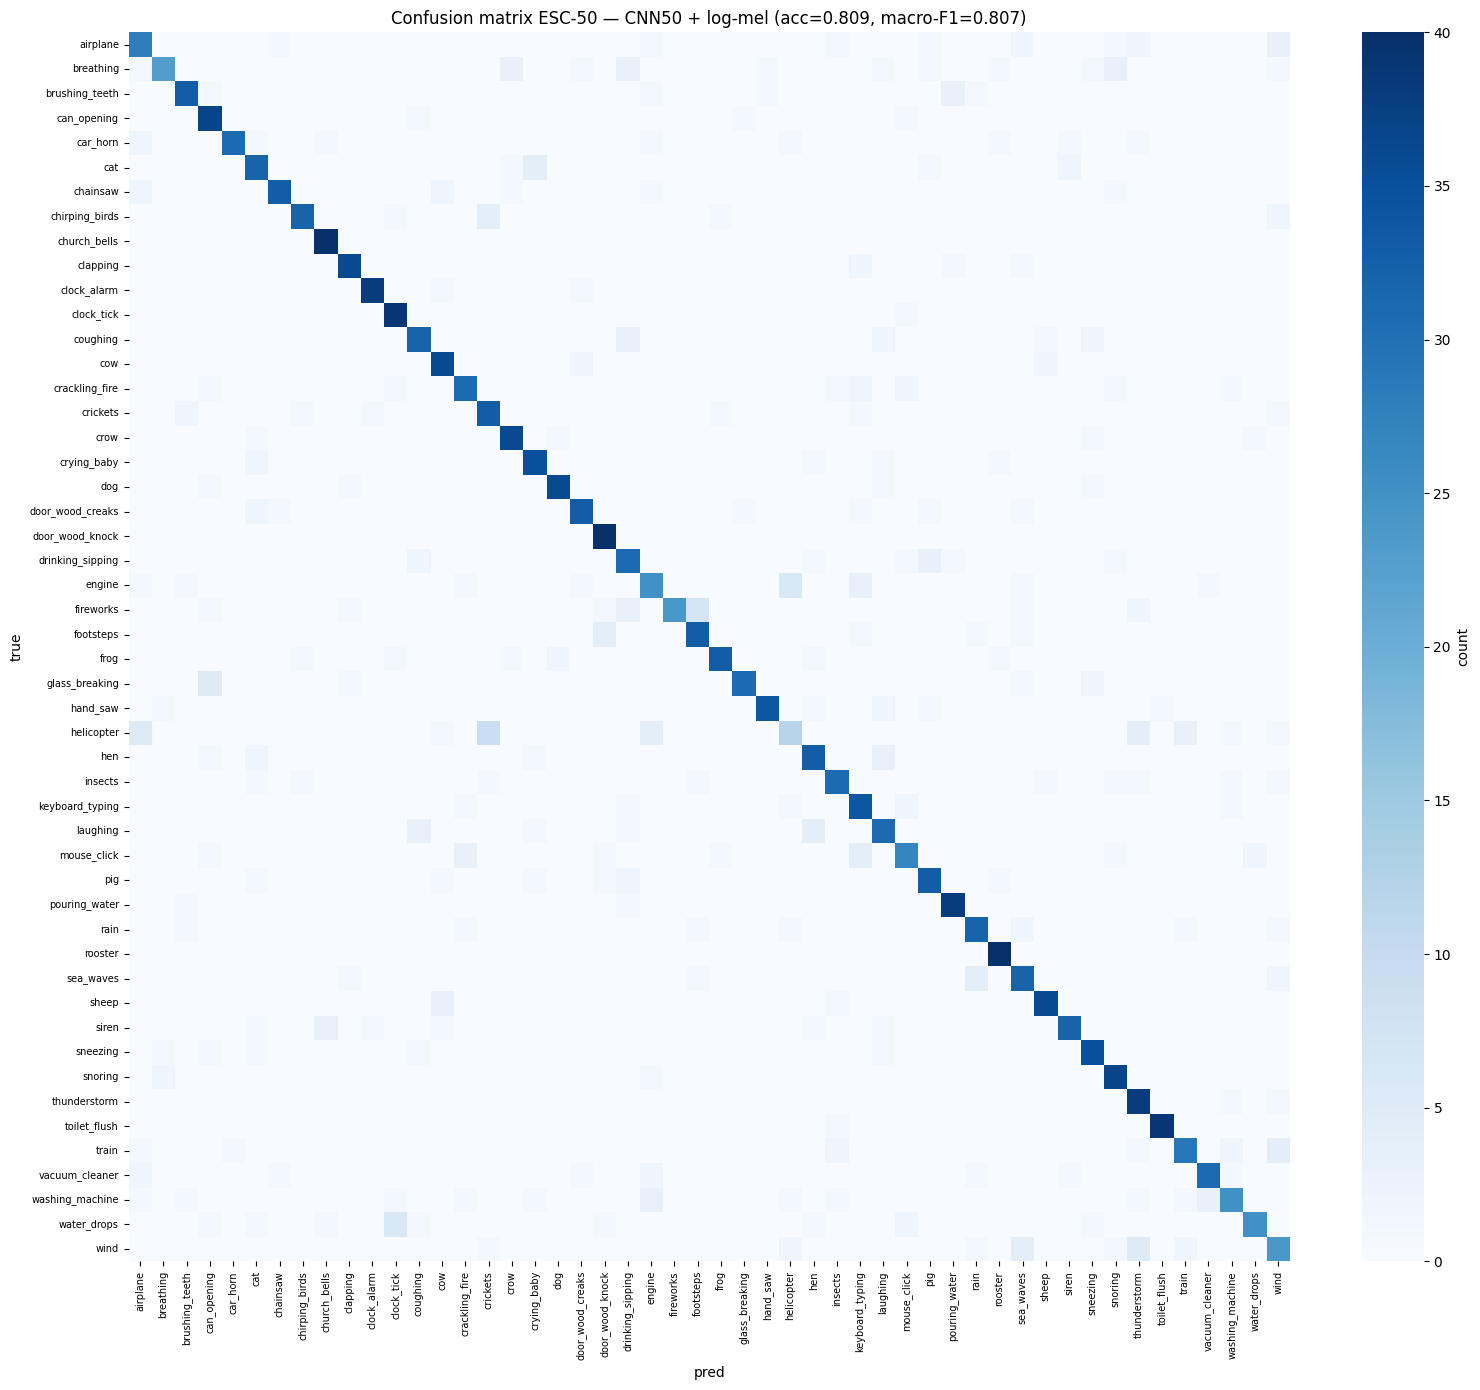


Топ-15 путаниц (истина → предсказание):
   9  helicopter           → crickets
   7  fireworks            → footsteps
   6  water_drops          → clock_tick
   6  engine               → helicopter
   5  wind                 → thunderstorm
   5  helicopter           → airplane
   5  glass_breaking       → can_opening
   4  wind                 → sea_waves
   4  train                → wind
   4  sea_waves            → rain
   4  mouse_click          → keyboard_typing
   4  laughing             → hen
   4  helicopter           → thunderstorm
   4  helicopter           → engine
   4  footsteps            → door_wood_knock

Топ-10 ХУДШИХ классов (F1):
           class       f1  support
      helicopter 0.375000     40.0
            wind 0.592593     40.0
          engine 0.632911     40.0
        airplane 0.674699     40.0
 washing_machine 0.684932     40.0
       breathing 0.686567     40.0
     mouse_click 0.710526     40.0
drinking_sipping 0.729412     40.0
     water_drops 0.735294    

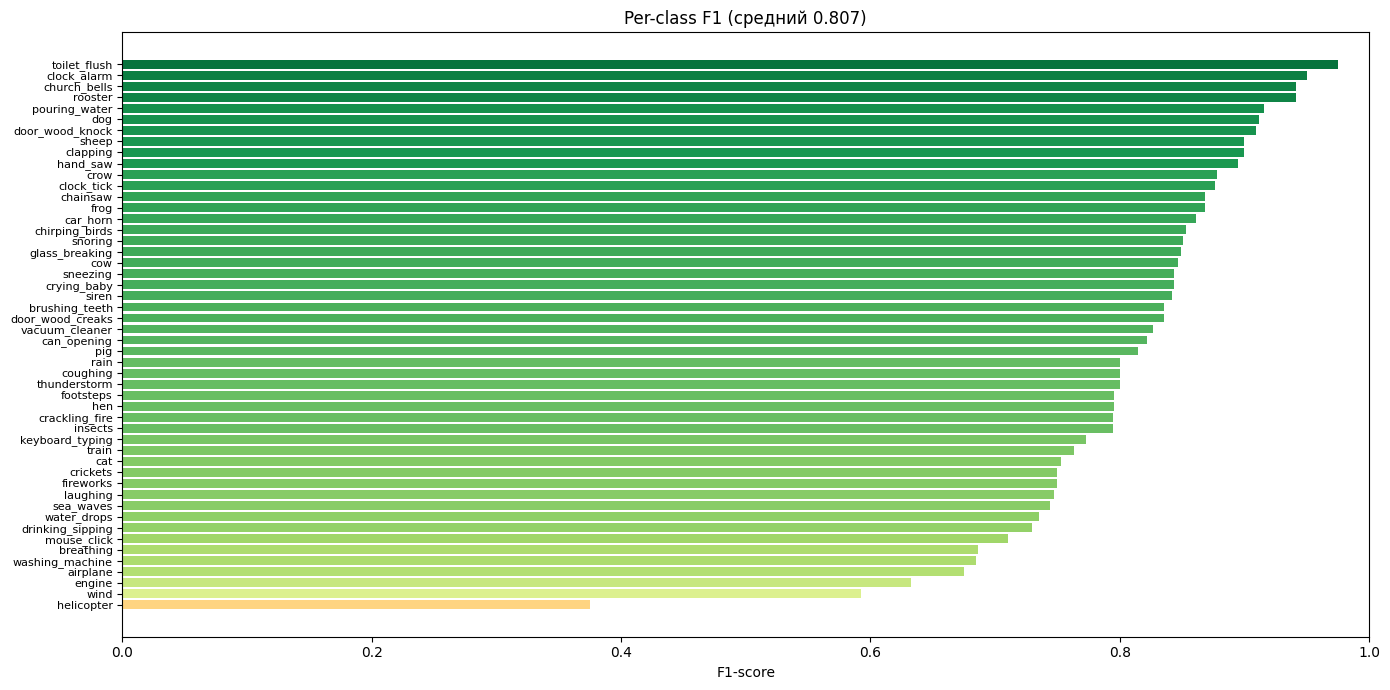

In [20]:
best = max(results, key=lambda r: r["acc"])
cm = confusion_matrix(best["y_true"], best["y_pred"], labels=range(50))

# Матрица 50x50
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, annot=False, cmap="Blues",
            xticklabels=classes, yticklabels=classes, ax=ax,
            cbar_kws={"label": "count"})
ax.set_xlabel("pred"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix ESC-50 — {best['model']} "
             f"(acc={best['acc']:.3f}, macro-F1={best['f1']:.3f})")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "confusion_matrix_50.png", dpi=120, bbox_inches="tight")
plt.show()

# Топ-15 путаниц
pairs = [(cm[i, j], classes[i], classes[j])
         for i in range(50) for j in range(50)
         if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)
print("\nТоп-15 путаниц (истина → предсказание):")
for n, a, b in pairs[:15]:
    print(f"  {n:2d}  {a:20s} → {b}")

# Per-class F1
report = classification_report(best["y_true"], best["y_pred"],
                                target_names=classes, output_dict=True,
                                zero_division=0)
per_class = pd.DataFrame({
    "class": classes,
    "f1":   [report[c]["f1-score"] for c in classes],
    "support": [report[c]["support"] for c in classes],
}).sort_values("f1")

print("\nТоп-10 ХУДШИХ классов (F1):")
print(per_class.head(10).to_string(index=False))
print("\nТоп-10 ЛУЧШИХ классов (F1):")
print(per_class.tail(10).to_string(index=False))

# Визуализация per-class F1
fig, ax = plt.subplots(figsize=(14, 7))
per_sorted = per_class.sort_values("f1")
colors = plt.cm.RdYlGn(per_sorted["f1"].values)
ax.barh(per_sorted["class"], per_sorted["f1"], color=colors)
ax.set_xlim(0, 1); ax.set_xlabel("F1-score")
ax.set_title(f"Per-class F1 (средний {per_class['f1'].mean():.3f})")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "per_class_f1_50.png", dpi=120, bbox_inches="tight")
plt.show()

per_class.to_csv(PROJECT_DIR / "per_class_f1_50.csv", index=False)

t-SNE на 400 примерах fold 1...


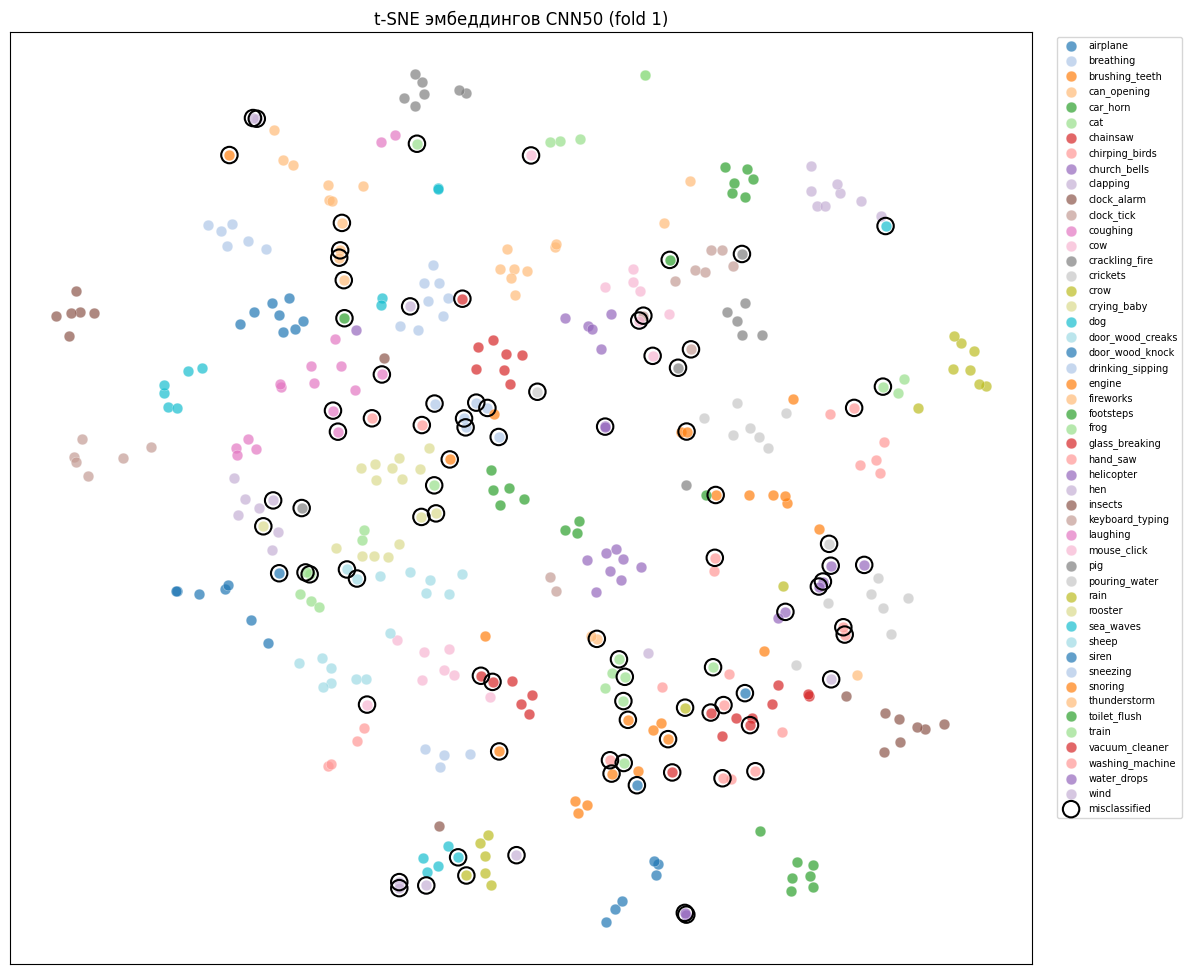

Silhouette score (512D): 0.115


In [21]:
from sklearn.manifold import TSNE

def extract_embedding_50(model, X, batch_size=64):
    """Последний Linear-слой даёт логиты; берём предпоследний (512D у CNN50)."""
    model.eval()
    loader = DataLoader(AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    original_head = model.head
    model.head = nn.Sequential(*list(original_head)[:-1])
    embs = []
    with torch.no_grad():
        for Xb, _ in loader:
            embs.append(model(Xb.to(device)).cpu().numpy())
    model.head = original_head
    return np.concatenate(embs)


# Берём модель с первого фолда
fold_to_use = 1
tr, te = folds[fold_to_use - 1]
model_tsne = CNN50().to(device)
model_tsne.load_state_dict(torch.load(PROJECT_DIR / f"cnn50_fold{fold_to_use}.pt",
                                        map_location=device))
emb_test = extract_embedding_50(model_tsne, X_mel[te])
y_test   = y_all[te]
pred_test = probs_cnn[:len(te)].argmax(1) if fold_to_use == 1 else predict_probs(model_tsne, X_mel[te]).argmax(1)

print(f"t-SNE на {len(te)} примерах fold {fold_to_use}...")
tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto",
            init="pca", random_state=SEED, n_iter=1000)
emb_2d = tsne.fit_transform(emb_test)

fig, ax = plt.subplots(figsize=(12, 10))
cmap = plt.cm.tab20
for i, cls in enumerate(classes):
    mask = y_test == i
    if mask.sum() == 0: continue
    ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1], s=60, alpha=0.7,
               color=cmap(i % 20), edgecolors="white", linewidth=0.3,
               label=cls if mask.sum() > 0 else None)
wrong = pred_test != y_test
if wrong.sum() > 0:
    ax.scatter(emb_2d[wrong, 0], emb_2d[wrong, 1], s=140, facecolors="none",
               edgecolors="black", linewidth=1.5, label="misclassified")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, ncol=1)
ax.set_title(f"t-SNE эмбеддингов CNN50 (fold {fold_to_use})")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(PROJECT_DIR / "tsne_50.png", dpi=120, bbox_inches="tight")
plt.show()

from sklearn.metrics import silhouette_score
sil = silhouette_score(emb_test, y_test)
print(f"Silhouette score (512D): {sil:.3f}")